# Experiment 2.4 · LeNet-5 In-Depth Testing

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

# the repository root in my computer
REPO_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

# numpy setting
np.set_printoptions(precision=4, suppress=True)

## Part 4A - Training to 97%

**Question 1**

*Predict how many training examples your CNN will need before validation accuracy first reaches 97%, and how many your FFNet needed (count examples, not epochs). Explain your numbers. (Recall from Lab 1 how many times each C1 weight is used for one image.)*

### Experiment

**CNN:**
- Using FFNet (784 input → 300 ReLU → 10 softmax output)
- +/- 0.05 weight initialization
- 0.3 learning rate
- 32 batch size
- Binary pixels (if pixel value >= 128 → 1, else 0)
- Target of training accuracy >= 99%, testing accuracy >= 97%

**FFNet (trained in FFNet Lab 4):**
- 784 input → 300 ReLU → 10 softmax output
- +/- 0.05 weight initialization
- 0.3 learning rate
- 32 batch size


### Prediction

For CNN, I believe that the testing accuracy would first reach 97% after around 20,000 examples.

For FFNet, I believe that it would take 300,000 examples for testing accuracy to first reach 97%.

### Because

My starting point is the Lab 2 T5 run, in which used the same seed and image order as this run's first epoch. There, validation was:
- 93.48% after 5,000 examples
- 96.29% after 10,000 examples
- 96.68% after 15,000 examples

And reached 97.30% at around 20,000 examples. Since the first epoch of the 2 epoch run would repeat the run from Lab 2 T5 (because of the same exact set-up), I expect that the run would reach 97% again at the 20,000 examples.

The FFNet lab stopped at the first epoch with both training accuracy >= 99% and test accuracy >= 97%. For the best setup, that was epoch 5, so 5 times 60,000 = 300,000 examples, which is my estimation fo the FFNet performance.

The FFNet has 238,510 trainable parameters and LeNet-5 has 61706 trainable parameters, so the FFNet has around 4 times as many values to learn. If both networks needed the same amount of evidence per parameter update, that alone would make the CNN need about 4 times fewer examples. In addition, CNN's parameters also get far more evidence from each image. In FFNet, each weights in the first layer only see one pixel per image and get no gradient when that pixel is 0. In LeNet, each C1 weight is used at 784 positions and each C3 weight at 10 * 10 = 100 positions per image, so the early layers learn from many places in every image. Indicatiing that there is extra advantage on training on the image from the trainable parameters (minimum bar roughly about 4 times).

**Question 2**

*Run java MNISTTrainer 2 1 (2 epochs, seed 1). Plot training accuracy and validation accuracy against examples seen from learning_curve.csv, and paste the plot. Report the number of examples to 97% and the test accuracy.*

=== LeNet-5 MNIST Trainer ===

Seed 1, 2 epochs, 50000 training / 10000 validation images


Validation accuracy before training: 7.61%

 examples   mean train loss   train acc   validation acc   time


     5000            0.7963      72.28%           93.48%     5.9s


    10000            0.2026      93.84%           96.29%    11.8s


    15000            0.1624      95.22%           96.68%    17.9s


...

  sigma = 0.1:  98.00%


  sigma = 0.2:  97.65%


  sigma = 0.3:  96.93%


  sigma = 0.4:  94.61%


  sigma = 0.5:  89.19%


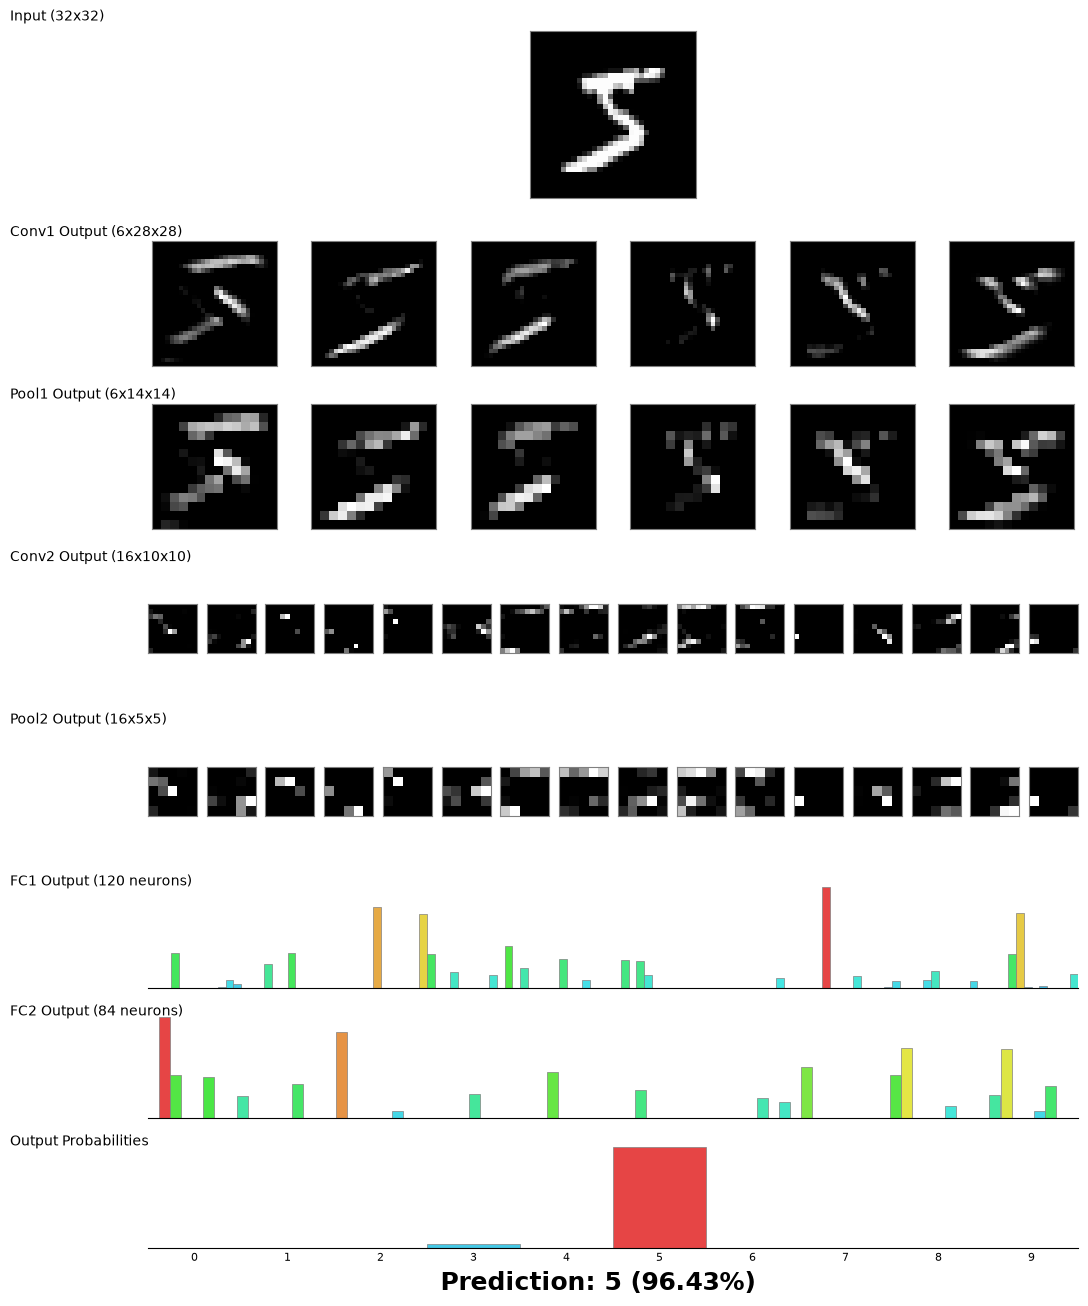

In [2]:
from lenet5 import mnisttrainer

# python port of `java MNISTTrainer 2 1`: about 4 minutes; writes learning_curve.csv next to this notebook
mnist_net = mnisttrainer.main(epochs=2, seed=1)

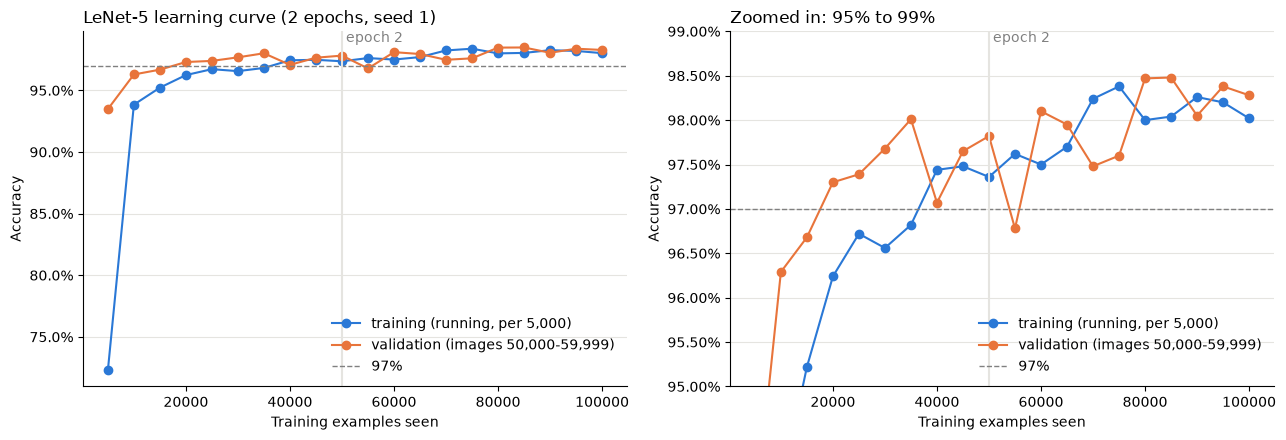

validation first >= 97% at 20000 examples
 examples_seen  mean_train_loss  train_accuracy  validation_accuracy
          5000         0.796320          0.7228               0.9348
         10000         0.202596          0.9384               0.9629
         15000         0.162432          0.9522               0.9668
         20000         0.120653          0.9624               0.9730
         25000         0.106609          0.9672               0.9739
         30000         0.116858          0.9656               0.9768
         35000         0.101747          0.9682               0.9801
         40000         0.089954          0.9744               0.9707
         45000         0.094696          0.9748               0.9765
         50000         0.093426          0.9736               0.9782
         55000         0.075790          0.9762               0.9678
         60000         0.088889          0.9750               0.9810
         65000         0.076770          0.9770              

In [3]:
TRAIN_COLOR = "#2a78d6"
VALIDATION_COLOR = "#e8743b"
GRID_COLOR = "#e5e4e0"

curve = pd.read_csv("learning_curve.csv")

# left: the whole run, right: the same curves zoomed in on 95-99% so the jagged part is visible
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, title in zip(axes, ["LeNet-5 learning curve (2 epochs, seed 1)", "Zoomed in: 95% to 99%"]):
    ax.plot(curve["examples_seen"], curve["train_accuracy"], marker="o", color=TRAIN_COLOR, label="training (running, per 5,000)")
    ax.plot(curve["examples_seen"], curve["validation_accuracy"], marker="o", color=VALIDATION_COLOR, label="validation (images 50,000-59,999)")
    ax.axhline(0.97, color="gray", linestyle="--", linewidth=1, label="97%")
    ax.axvline(50000, color=GRID_COLOR, linewidth=1.5)
    ax.text(50000, 0.97, " epoch 2", color="gray", transform=ax.get_xaxis_transform())

    ax.set_title(title, loc="left")
    ax.set_xlabel("Training examples seen")
    ax.set_ylabel("Accuracy")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="lower right")

axes[1].set_ylim(0.95, 0.99)
fig.tight_layout()
plt.show()

first_97 = curve.loc[curve["validation_accuracy"] >= 0.97, "examples_seen"].iloc[0]
print(f"validation first >= 97% at {first_97} examples")
print(curve.to_string(index=False))

**Output** (2 epochs, seed 1), from the cell above:

```
 examples   mean train loss   train acc   validation acc
     5000            0.7963      72.28%           93.48%
    10000            0.2026      93.84%           96.29%
    15000            0.1624      95.22%           96.68%
    20000            0.1207      96.24%           97.30%
    25000            0.1066      96.72%           97.39%
    30000            0.1169      96.56%           97.68%
    35000            0.1017      96.82%           98.01%
    40000            0.0900      97.44%           97.07%
    45000            0.0947      97.48%           97.65%
    50000            0.0934      97.36%           97.82%
    55000            0.0758      97.62%           96.78%
    60000            0.0889      97.50%           98.10%
    65000            0.0768      97.70%           97.95%
    70000            0.0594      98.24%           97.48%
    75000            0.0599      98.38%           97.60%
    80000            0.0679      98.00%           98.47%
    85000            0.0647      98.04%           98.48%
    90000            0.0610      98.26%           98.05%
    95000            0.0634      98.20%           98.38%
   100000            0.0634      98.02%           98.28%
```

- Validation accuracy first reached 97% at the **20,000** examples (97.30%). Checkpoints are every 5,000 examples, so the real crossing is somewhere between 15,001 and 20,000.
- The alidation fell back below 97% once, at 55,000 (96.78%). It has been at or above 97% at every checkpoint from **60,000** on.
- Test accuracy (evaluated once, at the end): 98.20%.
- The first epoch is identical to the 1-epoch run in Lab 3 T5 (same seed, same image order), so the first 10 rows match it exactly. The second epoch adds about 0.5 points: validation goes from 97.82% to 98.28%, and test accuracy goes from 97.66% to 98.20%.

**Question 3**

*The validation curve is jagged: sometimes it drops by a percentage point between two checkpoints. Explain why training one example at a time with a fixed learning rate produces this. What does it mean for “examples to reach 97%” as a measurement, and how would you make that measurement trustworthy?*

The trainer calls net.step(0.01) after every single image (batch size 1). Each step moves all 61,706 weights along the gradient of one image's loss, and that gradient is a very noisy estimate of the gradient over the whole training set. The steps do not get smaller as training goes on, so near a minimum the true gradient is small, but each single-image gradient is not, so the weights never settle. They keep moving around the minimum, and each checkpoint is a snapshot of wherever they are at that moment.

For "examples to reach 97%", it is the *first time* a noisy curve crosses a line, so it records the trend plus whichever random upward spike happened first. In this run it gives 20,000, but validation was below 97% again at 55,000, and stayed above only from 60,000 on.

To make the measurement trustworthy, you could repeat the run with several seeds and shuffled image orders, and report the median/median and the spread instead of just one number, or you could reduce the noise in the curve by decaying the learning rate over time making each depend less on the last few examples.

**Question 4**

*An earlier version of this assignment stopped training as soon as test accuracy reached 97% and reported that number. What is wrong with the reported number? Why does this lab watch a separate validation set and touch the test set only once? Compare your final training and validation accuracy: is there any sign of overfitting after 2 epochs?*

If training stops the first time *test* accuracy reaches 97%, the test set is being used to choose the stopping point. As Question 3 shows, accuracy goes up and down by about a point between checkpoints, so stopping on the first ≥ 97% reading stops on a reading that is depends on the chance.

Every decision made while looking at a set (when to stop, which learning rate, which initialization, which run to keep) fits the result to that set a little. The validation set (images 50,000–59,999) takes all of those decisions, and its numbers are allowed to be optimistic. The test set is never used for any decision and is evaluated once, at the end, so 98.20% is the true estimate of accuracy on new digits.

There is no sign of overfitting:

| | end of epoch 1 (50,000) | end of epoch 2 (100,000) | mean of last 5 checkpoints, epoch 1 | mean of last 5 checkpoints, epoch 2 |
|---|---|---|---|---|
| training accuracy | 97.36% | 98.02% | 97.30% | 98.06% |
| validation accuracy | 97.82% | 98.28% | 97.65% | 98.33% |

Training and validation accuracy are about equal and the final training accuracy (98.02%) is actually below validation (98.28%). Overfitting would show as training accuracy pulling clearly above validation.

### Result

| | Prediction | Result |
|---|---|---|
| CNN, examples until validation first ≥ 97% | about 20,000 | **20,000** (97.30%), between 15,001 and 20,000 at 5,000-example resolution |
| CNN, examples until validation *stays* ≥ 97% | (not predicted) | **60,000** (it fell to 96.78% at 55,000) |
| FFNet, examples to 97% | about 300,000 | not re-run here; 300,000 (epoch 5 × 60,000) from the FFNet lab |
| CNN test accuracy after 2 epochs | — | **98.20%** (validation 98.28%) |

The CNN prediction was correct: 97% at 20,000 examples. Using the FFNet lab's number, the CNN needed about 300,000 / 20,000 = 15 times fewer examples to reach 97%.

### Explannation

Each C1 kernel weight is shared across every output position. With the 32 by 32 padded input and a 5 by 5 kernel, C1 produces a 28 by 28 output, so each C1 weight is used 784 times per image. In the backward pass its gradient is the sum of delta * input over all 784 positions. One image therefore gives each C1 weight 784 small pieces of evidence, taken from every stroke and edge in the digit. In the same way, each convolution works the same way. In the FFNet, each first layer weight connects to one pixel, is used once per image, and gets zero gradient whenever that pixel is background (about 80% of MNIST pixels).

So, CNN structure has the advantage of not having to be learned as each C1 unit has a 5 by 5 receptive field, and after S2, C3 and S4 each C5 unit sees the whole image. The 2 by 2 max pooling in S2 and S4 makes the output tolerate small shifts. The FFNet has to just learn "a digit one pixel to the right is still the same digit" from examples, separately for each position. The CNN gets most of that from its structure.

After about 20,000 examples most digits are classified correctly with high confidence, so their error (p − y) is close to zero and they barely change the weights. The remaining gradient comes mostly from the hard and ambiguous digits. Each of those, at a fixed learning rate of 0.01, gives a full-size update that pushes every shared kernel. This keeps improving the average (the training loss keeps falling, 0.093 --> 0.063 over epoch 2), but it also moves the network back and forth by about a point of validation accuracy between checkpoints (Question 3).

### Reconciliation (what my mental model was missing):

**Expected:** validation first reaches 97% at about 20,000 examples, because the first epoch repeats the Lab 3 T5 run exactly. **Happened:** 20,000, exactly.

The prediction matched, but mostly because the first epoch was the same deterministic run I had already seen, not because my model of the network predicted it. What my mental model was missing that reaching 97% is not a state the network stays in, as I treated 97% as a line that, once crossed, stays crossed. The network fell back to 96.78% at 55,000 and only stayed above 97% from 60,000 on. With single-image SGD at a fixed learning rate, the weights keep moving around the minimum, so a first-crossing time includes a lot of luck.

## Part 4B - Looking inside

**Question 1**

*Predict what the six C1 feature maps of the trained network will show for the first training image (a 5). Then look: at the end of the run, MNISTTrainer opens the NetworkVisualizer for that image. Paste a screenshot.*

### Experiment

LeNet-5 (trained in Part 4A):
- 32 by 32 padded input --> C1 (6 maps, 5 by 5 kernels, ReLU) --> S2 (2 by 2 max pool)--> C3 (16 maps, ReLU) --> S4 (2 by 2 max pool) --> C5 (120, ReLU) --> F6 (84, ReLU) --> 10 softmax output
- +/- 0.1 weight initialization, biases start at 0
- 0.01 learning rate
- 1 batch size (one image at a time)
- Pixels scaled to 0-1 (pixel / 255)
- 2 epochs on the first 50,000 training images, seed 1

### Prediction

*Before looking at the visualizer output*

For C1, I believe that all six maps would still look like the 5, because each map is 28 by 28 and in the same position as the digit. But they would not be six copies of the same image as few maps would light up only the edges of the strokes at one orientation, some maps would light up only one side of a stroke (for example the top edge but not the bottom edge of the bar).

### Because

Each C1 map is one 5 by 5 kernel slid over the whole image with stride 1, so the map is a picture of where in the image the kernel's pattern appears. The kernel only sees a 5 by 5 patch, so in a 5 it can only see pieces of strokes, not the whole digit. The most common thing in a 5 by 5 patch of a digit is a piece of a stroke edge, so the kernels that help the loss the most are the ones that respond to stroke edges at some orientation.

A kernel with positive weights on one side and negative weights on the other side only gives a positive z on one side of a stroke, and the ReLU sets the other side to 0 (black). This is why I expect "one side of a stroke" maps. A kernel with mostly positive weights is more like a blur, so it gives a thick copy of the digit. If a kernel has mostly negative weights and a positive bias, the background (input 0, so z = bias) is brighter than the stroke, which would give an inverted map.

label: 5


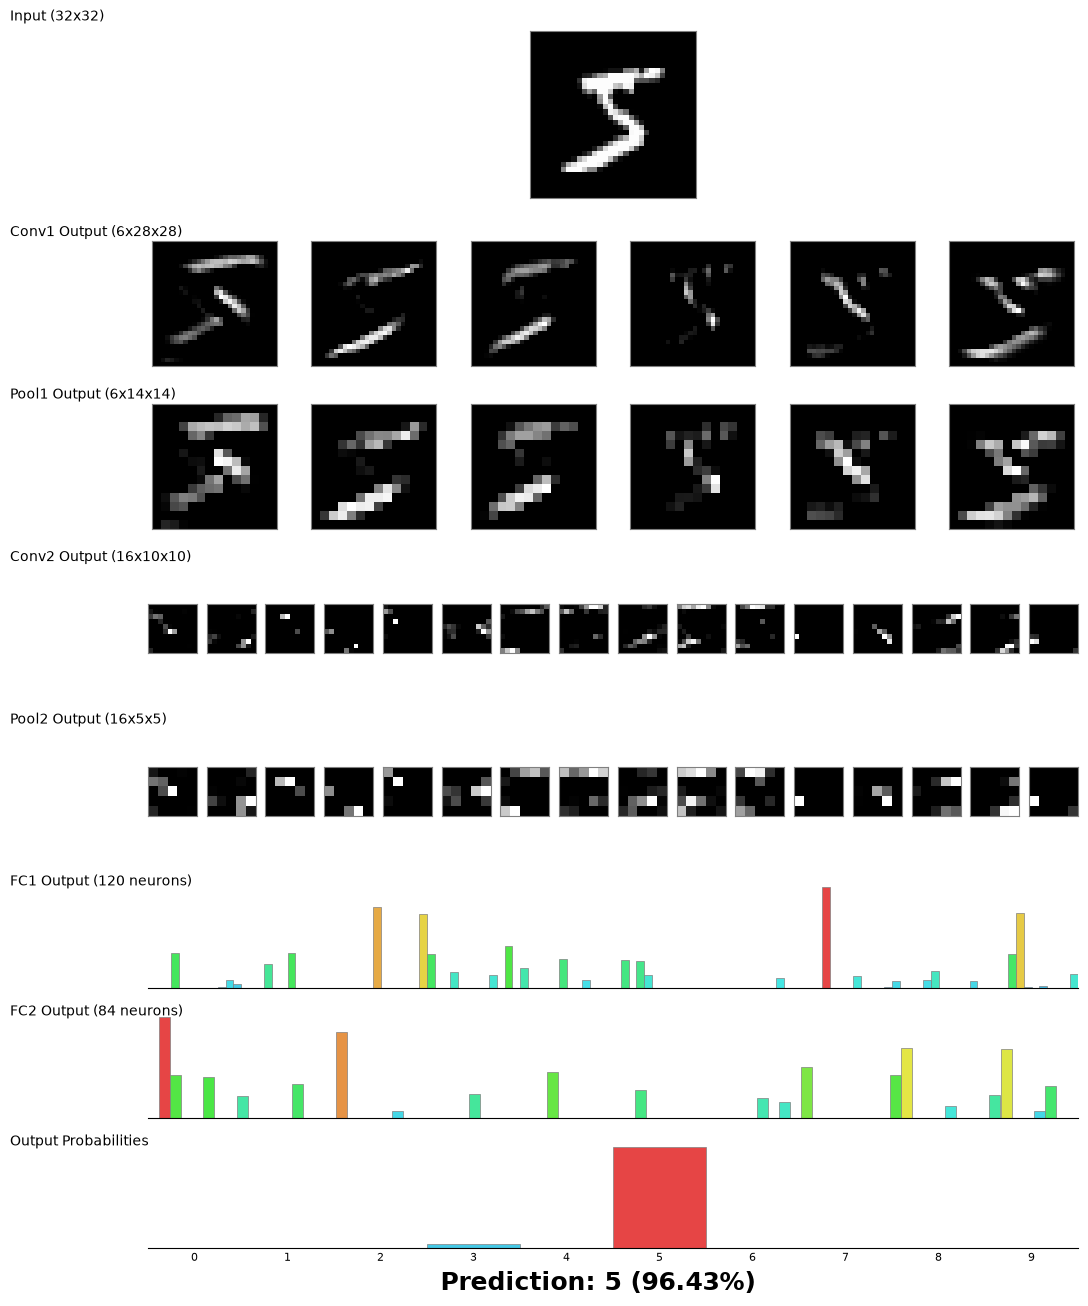

In [5]:
from lenet5.mnistloader import MNISTLoader
from lenet5.networkvisualizer import NetworkVisualizer

DATA_DIR = REPO_ROOT / "data" / "mnist"
mnist = MNISTLoader(
    DATA_DIR / "train-images-idx3-ubyte",
    DATA_DIR / "train-labels-idx1-ubyte",
    DATA_DIR / "t10k-images-idx3-ubyte",
    DATA_DIR / "t10k-labels-idx1-ubyte"
)

# the trained network from Part 4A on the first training image (a 5)
first_image = mnist.get_train_image(0)
print(f"label: {mnist.get_train_label(0)}")

viz = NetworkVisualizer(mnist_net)
viz.process_and_display(first_image)
viz.show()

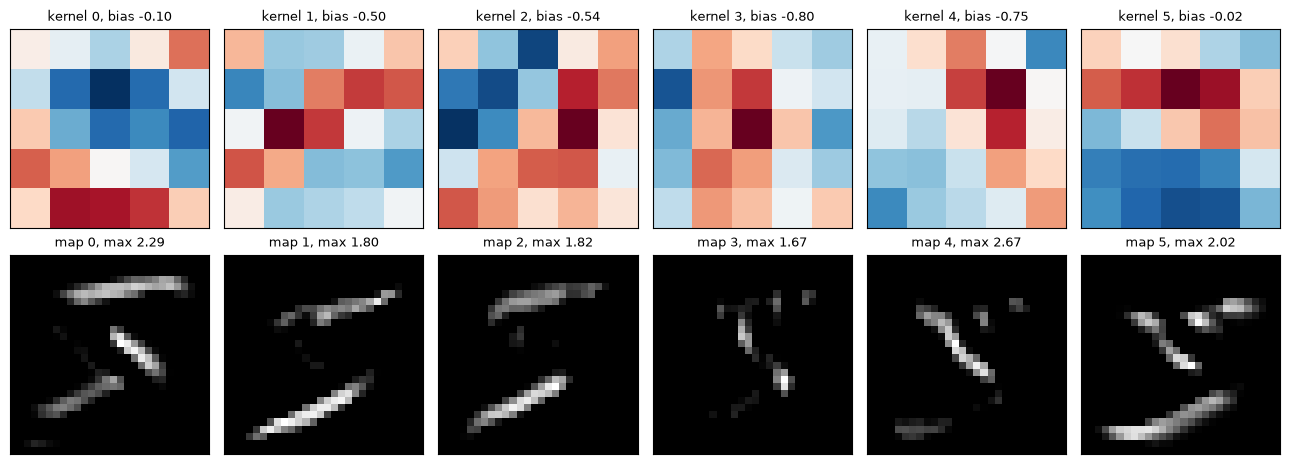

kernel 0 (bias -0.099):
[[ 0.0498 -0.0646 -0.226   0.0696  0.3977]
 [-0.1786 -0.5603 -0.7191 -0.5551 -0.14  ]
 [ 0.19   -0.3591 -0.5572 -0.4589 -0.5746]
 [ 0.4294  0.2934  0.0081 -0.1203 -0.4018]
 [ 0.1458  0.6092  0.5925  0.5197  0.176 ]]
kernel 1 (bias -0.498):
[[ 0.2525 -0.2858 -0.2722 -0.0517  0.2106]
 [-0.4929 -0.3202  0.3882  0.5308  0.4688]
 [-0.0271  0.7583  0.5359 -0.0365 -0.2411]
 [ 0.4786  0.2882 -0.3312 -0.3103 -0.4302]
 [ 0.0571 -0.2843 -0.237  -0.1935 -0.0275]]
kernel 2 (bias -0.538):
[[ 0.1085 -0.1842 -0.4221  0.043   0.187 ]
 [-0.3283 -0.4093 -0.1772  0.3555  0.2431]
 [-0.4543 -0.2874  0.1497  0.4593  0.0644]
 [-0.0962  0.186   0.2781  0.2869 -0.0347]
 [ 0.2848  0.1945  0.0734  0.1567  0.0546]]
kernel 3 (bias -0.796):
[[-0.2232  0.2847  0.1383 -0.1584 -0.2554]
 [-0.6238  0.32    0.5125 -0.0365 -0.136 ]
 [-0.3654  0.2483  0.723   0.1998 -0.4149]
 [-0.3198  0.4176  0.3025 -0.1035 -0.2603]
 [-0.186   0.3146  0.2192 -0.0325  0.1878]]
kernel 4 (bias -0.750):
[[-0.0663  0.155

In [6]:
# each C1 kernel (top, red = positive, blue = negative) above its feature map for the first image (bottom)
c1_kernels = mnist_net.c1_layer.weights[:, 0]
c1_bias = mnist_net.c1_layer.bias.reshape(-1)
c1_maps = mnist_net.c1_layer.last_outputs[0]

fig, axes = plt.subplots(2, 6, figsize=(13, 4.8))
for m in range(6):
    limit = np.abs(c1_kernels[m]).max()
    axes[0, m].imshow(c1_kernels[m], cmap="RdBu_r", vmin=-limit, vmax=limit)
    axes[0, m].set_title(f"kernel {m}, bias {c1_bias[m]:+.2f}", fontsize=9)
    axes[1, m].imshow(c1_maps[m], cmap="gray", interpolation="nearest")
    axes[1, m].set_title(f"map {m}, max {c1_maps[m].max():.2f}", fontsize=9)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()

for m in range(6):
    print(f"kernel {m} (bias {c1_bias[m]:+.3f}):")
    print(c1_kernels[m])

The visualizer above shows the trained network on the first training image. It predicts 5 with 96.43%.

The six C1 maps (Conv1 Output row) all have a black background and only light up on parts of the strokes.

None of the maps is an inverted or blurred copy of the whole digit.

**Question 2**

*For at least three C1 maps, describe what they respond to: which strokes, which orientation, and which side of a stroke. Why are the C3 and S4 maps much harder to interpret?*

Using the kernels drawn above the maps (red = positive weight, blue = negative weight):

| Map | Kernel | Responds to |
|---|---|---|
| 0 | negative in the middle rows, positive in the bottom row | horizontal strokes, the top side of the stroke |
| 5 | positive in first row, negative in the bottom two rows | horizontal strokes, the bottom side stroke |
| 1 | positive band from bottom-left to top-right, negative in the other corners | diagonal strokes going bot-left to top-right |
| 2 | positive band along bottom-left to top-right, negative on the upper-left | diagonal strokes going bot-left to top-right with the upper-left side empty. |
| 3 | positive in the middle columns, negative in the left column and right column | vertical strokes, with the left side empty and partly right side empty |
| 4 | positive band from top-middle to bottom-right, negative bottom-left | steep strokes going down to the right |

C3 and S4 maps are much harder to interpret because:
- Each C3 kernel is 6 by 5 by 5 = 150 weights spread over all six S2 maps, so it responds to a combination of C1 features (for example "a horizontal top edge next to a vertical stroke"), not to pixels.
- Max pooling throws away the exact position inside each 2 by 2 block, so the maps no longer line up with the strokes.

**Question 3**

*MNISTTrainer also reports dead units: feature maps or units that never produce a positive output on 1,000 validation images. Explain what a dead unit is, and why a ReLU unit that is dead never recovers under gradient descent.*

The dead unit report for this run is:

```
Dead units (never positive on 1,000 validation images): C1 0/6, C3 0/16, C5 1/120, F6 0/84
```

A dead unit is a ReLU unit where z is <= 0 for every input, so its output is always 0. It has no effect on the prediction, so it is wasted capacity. Here only 1 of the 120 C5 units is dead, and the Lab 3 T5 run (1 epoch) also had 1 dead C5 unit.

It never recovers because of how the gradient goes through the ReLU. The derivative of ReLU is 0 when z <= 0, so for a dead unit delta = dC/da * 0 = 0 on every image. Its weight gradient is the sum of delta * input, and its bias gradient is the sum of delta, so both are exactly 0. Gradient descent then never changes its weights or bias, so z stays <= 0 and the unit stays dead. The weights going out of the unit also get zero gradient, because the input they multiply (the unit's output) is 0.

### Result

| | Prediction | Result |
|---|---|---|
| All six C1 maps look like the 5 | yes | partly. Maps 0, 1, 2 and 5 show most of the 5, and maps 3 and 4 only show one part |
| Maps for stroke edges at one orientation | yes | yes. Horizontal (0, 5), diagonals from bottom left to top right (1, 2), vertical (3), diagonals top left to bottom right (4) |
| Maps for one side of a stroke | yes | yes. Map 0 = top side, map 5 = bottom side of horizontal strokes |

The network predicts the first training image as 5 with 96.43%.

### Explannation

Each C1 kernel is a 5 by 5 pattern and the map is where that pattern appears in the image. A kernel with a positive band and negative weights on one side gives positive z only on the side of the stroke that matches, and ReLU sets the rest to 0. This is why the maps show one orientation, and for kernels 0 and 5 only one side of a stroke.

Maps 3 and 4 only show part of the digit because this particular 5 has only a short vertical stem and one diagonal from top left to bottom right stroke. On a 1 or a 7, map 3 or map 4 would show much more.e

### Reconciliation (what my mental model was missing):

**Expected:** six maps that all look like the 5, some for one orientation or one side of a stroke.

**Happened:** the orientation and one-side maps were right.

What my mental model was missing is the role of the bias. I thought of the C1 bias as a small offset that stays near 0, so I expected some maps to have a gray or bright background. Instead, every C1 bias was trained to a negative value, which works as a threshold: a map only turns on where its pattern clearly matches, and everything else is 0.

## Part 4C - How sensitive is training?

*Your Lab 3 run java MNISTTrainer 1 1 (learning rate 0.01, initial weights in [−0.1, 0.1)) is the baseline. You now change one constant at a time in LeNet5, recompile, and run one epoch with seed 1:*

| Run | Learning rate | Initial weights |
| --- | --- | --- |
| baseline (from Lab 3) | 0.01 | [-0.1, 0.1) |
| slow | 0.001 | [-0.1, 0.1) |
| fast | 0.1 | [-0.1, 0.1) |
| small start | 0.01 | [-0.05, 0.05) |
| large start | 0.01 | [-0.3, 0.3) |

**Question 1**

*Predict for each of the four new runs: the shape of the training-loss curve, the validation accuracy after one epoch, and whether the dead-unit counts will change.*

### Experiment

- Same LeNet-5 and trainer as Part 4A, 1 epoch (50,000 images), seed 1, batch size 1
- One constant changed per run (table above). Instead of editing training_config.py / model_config.py, the cell below sets the trainer's learning rate and passes the weight range to LeNet5, which does the same thing.
- Baseline is re-run in the same cell so all five runs are in one table and one plot

### Prediction

| Run | Training-loss curve | Validation after 1 epoch | Dead units |
|---|---|---|---|
| slow (0.001) | stays near 2.30 for longer, then falls slowly and smoothly | about 93% | same as baseline |
| fast (0.1) | falls fast at first, then jumps up and stays at about 2.30 | about 10% (collapses) | many more, a whole layer dead |
| small start (±0.05) | flat near 2.30 at the start for longer than baseline, then like baseline | about 97% | same as baseline |
| large start (±0.3) | starts much higher than 2.30, drops fast, noisier | about 96% | more than baseline |

### Because

The learning rate sets the size of each step. At 0.001 every step is 10 times smaller than baseline, so 50,000 images do the work of about 5,000 baseline images (baseline was 93.48% at 5,000). At 0.1 one bad image can push a bias far negative, and a ReLU unit that is pushed negative gets no gradient again (Part 4B Q3), so a big step can kill units for good. If every unit in a layer dies, the output is the same for every image and the loss sits at about 2.30.

The weight range scales the signal in every layer. With 5 weight layers, ±0.05 makes the output about 0.5^5 = 1/32 of baseline and the gradients are also smaller, so the network starts with a longer flat part, like the plateau in TrainingExample. ±0.3 makes the outputs about 3^5 times bigger, so the first predictions are very confident and very wrong, which gives a large loss and large first steps.

**Question 2**

*Run them. Make a table with, for each run, the examples to 97% (if reached), the validation accuracy after one epoch, the test accuracy and the dead-unit counts. Plot the mean training loss of the three learning rates on one graph.*

In [7]:
import contextlib
import io
import re
from functools import partial

from lenet5.lenet5 import LeNet5

# name: (learning rate, initial weights in [-range, range))
RUNS = {
    "baseline": (0.01, 0.1),
    "slow": (0.001, 0.1),
    "fast": (0.1, 0.1),
    "small start": (0.01, 0.05),
    "large start": (0.01, 0.3),
}

original = (mnisttrainer.LEARNING_RATE, mnisttrainer.LeNet5, mnisttrainer.LEARNING_CURVE_PATH, mnisttrainer.has_display)


def curve_path(name):
    return Path(f"learning_curve_{name.replace(' ', '_')}.csv")


def run_one_epoch(name, learning_rate, weight_range):
    # same as changing LEARNING_RATE / WEIGHT_LOW / WEIGHT_HIGH and running `java MNISTTrainer 1 1`
    mnisttrainer.LEARNING_RATE = learning_rate
    mnisttrainer.LeNet5 = partial(LeNet5, weight_low=-weight_range, weight_high=weight_range)
    mnisttrainer.LEARNING_CURVE_PATH = curve_path(name)
    mnisttrainer.has_display = lambda: False

    output = io.StringIO()
    with contextlib.redirect_stdout(output):
        net = mnisttrainer.main(epochs=1, seed=1)
    text = output.getvalue()
    print(f"===== {name}: learning rate {learning_rate}, initial weights [-{weight_range}, {weight_range}) =====")
    print(text.split("Shifted test digits")[0])

    reached = re.search(r"first reached 97% after (\d+)", text)
    dead = re.search(r"C1 (\d+/\d+), C3 (\d+/\d+), C5 (\d+/\d+), F6 (\d+/\d+)", text)
    return net, {
        "examples to 97%": int(reached.group(1)) if reached else "not reached",
        "validation after 1 epoch": f"{100 * pd.read_csv(curve_path(name))['validation_accuracy'].iloc[-1]:.2f}%",
        "test accuracy": re.search(r"TEST accuracy \(reported once\): ([\d.]+%)", text).group(1),
        "dead C1, C3, C5, F6": ", ".join(dead.groups()),
    }


nets, results = {}, {}
for name, (learning_rate, weight_range) in RUNS.items():
    nets[name], results[name] = run_one_epoch(name, learning_rate, weight_range)

(mnisttrainer.LEARNING_RATE, mnisttrainer.LeNet5, mnisttrainer.LEARNING_CURVE_PATH, mnisttrainer.has_display) = original

===== baseline: learning rate 0.01, initial weights [-0.1, 0.1) =====
=== LeNet-5 MNIST Trainer ===

Seed 1, 1 epochs, 50000 training / 10000 validation images
Validation accuracy before training: 7.61%

 examples   mean train loss   train acc   validation acc   time
     5000            0.7963      72.28%           93.48%     6.6s
    10000            0.2026      93.84%           96.29%    13.3s
    15000            0.1624      95.22%           96.68%    19.6s
    20000            0.1207      96.24%           97.30%    25.9s
    25000            0.1066      96.72%           97.39%    32.2s
    30000            0.1169      96.56%           97.68%    38.6s
    35000            0.1017      96.82%           98.01%    45.1s
    40000            0.0900      97.44%           97.07%    51.4s
    45000            0.0947      97.48%           97.65%    57.5s
    50000            0.0934      97.36%           97.82%    64.0s

Validation accuracy first reached 97% after 20000 training examples.
TE

In [ ]:
print(pd.DataFrame(results).T.to_string())

            examples to 97% validation after 1 epoch test accuracy         dead C1, C3, C5, F6
baseline              20000                   97.82%        97.66%      0/6, 0/16, 1/120, 0/84
slow            not reached                   96.40%        96.38%      0/6, 0/16, 3/120, 0/84
fast            not reached                    9.91%         9.80%  3/6, 15/16, 107/120, 84/84
small start           30000                   98.04%        97.80%      0/6, 0/16, 0/120, 0/84
large start     not reached                   96.23%        96.23%      0/6, 0/16, 0/120, 0/84


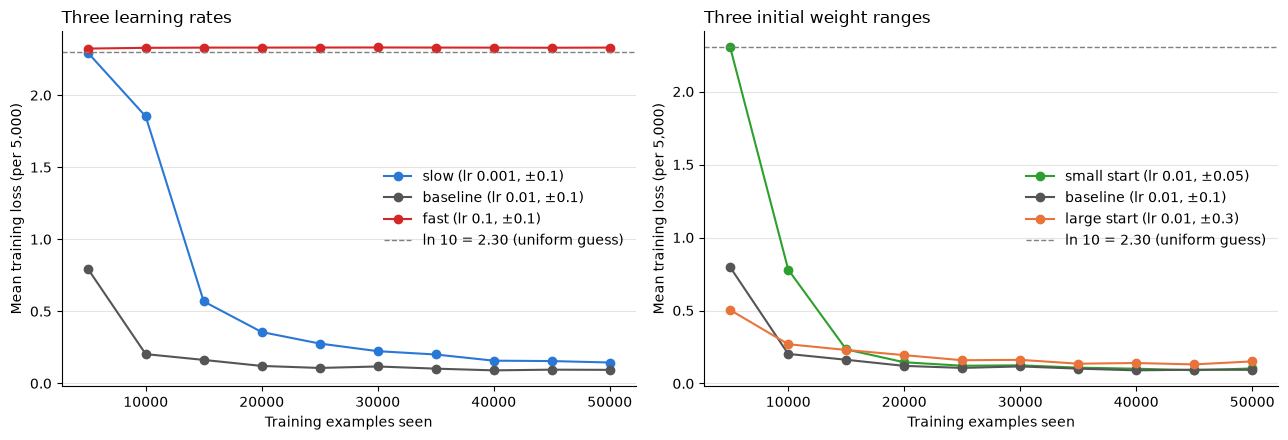

In [ ]:
RUN_COLORS = {"slow": "#2a78d6", "baseline": "#555555", "fast": "#d62728", "small start": "#2ca02c", "large start": "#e8743b"}


def plot_loss(ax, names, title):
    for name in names:
        curve = pd.read_csv(curve_path(name))
        learning_rate, weight_range = RUNS[name]
        ax.plot(curve["examples_seen"], curve["mean_train_loss"], marker="o", color=RUN_COLORS[name],
                label=f"{name} (lr {learning_rate}, ±{weight_range})")
    ax.axhline(np.log(10), color="gray", linestyle="--", linewidth=1, label="ln 10 = 2.30 (uniform guess)")
    ax.set_title(title, loc="left")
    ax.set_xlabel("Training examples seen")
    ax.set_ylabel("Mean training loss (per 5,000)")
    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_loss(axes[0], ["slow", "baseline", "fast"], "Three learning rates")
plot_loss(axes[1], ["small start", "baseline", "large start"], "Three initial weight ranges")
fig.tight_layout()
plt.show()

In [ ]:
# what the fast network predicts on the 10,000 test images
from lenet5.padded_input import forward

test_labels = np.array([mnist.get_test_label(i) for i in range(mnist.get_num_test_images())])
fast_predictions = np.array([np.argmax(forward(nets["fast"], mnist.get_test_image(i))) for i in range(len(test_labels))])

print("test images per digit:   ", np.bincount(test_labels, minlength=10))
print("fast predictions per digit:", np.bincount(fast_predictions, minlength=10))
print(f"largest digit share of the test set: {np.bincount(test_labels).max() / len(test_labels):.2%}")

test images per digit:    [ 980 1135 1032 1010  982  892  958 1028  974 1009]
fast predictions per digit: [10000     0     0     0     0     0     0     0     0     0]
largest digit share of the test set: 11.35%


In [ ]:
# the three starting networks (seed 1) before any training, on 1,000 validation images
for weight_range in (0.05, 0.1, 0.3):
    net = LeNet5(seed=1, weight_low=-weight_range, weight_high=weight_range)
    losses, top_probabilities = [], []
    c5_alive = np.zeros(net.c5_layer.out_channels, dtype=bool)
    for i in range(mnisttrainer.VAL_START, mnisttrainer.VAL_START + 1000):
        output = forward(net, mnist.get_train_image(i))
        losses.append(mnisttrainer.compute_loss(output, mnist.get_train_label(i)))
        top_probabilities.append(output.max())
        c5_alive |= np.any(net.c5_layer.last_outputs[0] > 0, axis=(1, 2))
    print(f"±{weight_range}: loss {np.mean(losses):.3f}, mean top probability {np.mean(top_probabilities):.3f}, "
          f"dead C5 {np.sum(~c5_alive)}/120")

±0.05: loss 2.303, mean top probability 0.100, dead C5 9/120
±0.1: loss 2.303, mean top probability 0.102, dead C5 9/120


±0.3: loss 5.894, mean top probability 0.607, dead C5 9/120


| Run | Learning rate | Initial weights | Examples to 97% | Validation after 1 epoch | Test accuracy | Dead C1, C3, C5, F6 |
|---|---|---|---|---|---|---|
| baseline | 0.01 | ±0.1 | 20,000 | 97.82% | 97.66% | 0/6, 0/16, 1/120, 0/84 |
| slow | 0.001 | ±0.1 | not reached | 96.40% | 96.38% | 0/6, 0/16, 3/120, 0/84 |
| fast | 0.1 | ±0.1 | not reached | 9.91% | 9.80% | 3/6, 15/16, 107/120, 84/84 |
| small start | 0.01 | ±0.05 | 30,000 | 98.04% | 97.80% | 0/6, 0/16, 0/120, 0/84 |
| large start | 0.01 | ±0.3 | not reached | 96.23% | 96.23% | 0/6, 0/16, 0/120, 0/84 |

The baseline re-run gives exactly the Lab 3 T5 numbers. Before training, all three starting networks have 9/120 dead C5 units. The loss is 2.303 for ±0.05 and ±0.1, and 5.894 for ±0.3 (average top probability 0.61, so it is confident and wrong).

**Question 3**

*Explain and reconcile each result. In particular, what happened at learning rate 0.1: did the loss explode, or did something else happen? Use the dead-unit report and the test accuracy as evidence: if the network gave the same answer for every image, which accuracy would you expect? (The test set contains between 892 and 1,135 images of each digit.) How does the small start relate to what you saw with TrainingExample in Lab 3?*

### Result

| Run | Predicted loss curve / validation / dead | Result |
|---|---|---|
| slow | flat near 2.30 longer, then slow / about 93% / same | flat at 2.30 for the first 5,000, then slow / 96.40% / C5 3 (baseline 1) |
| fast | falls, then jumps up to 2.30 / about 10% / many | at 2.32 to 2.33 from the first checkpoint on / 9.91% / C1 3, C3 15, C5 107, F6 84 (all) |
| small start | flat near 2.30 longer, then like baseline / about 97% / same | flat at 2.30 for the first 5,000, then caught up / 98.04% / none |
| large start | starts much higher, drops fast, noisier / about 96% / more | starts at 5.89, but the first 5,000 average (0.50) is *lower* than baseline (0.80), noisier / 96.23% / none |

### Explannation

**Slow:** each step is 10 times smaller, so for the first 5,000 images the output stays close to uniform (loss 2.30), and after 50,000 images it is only at about where baseline was after 10,000.

**Fast:** the loss did not explode. It went to a flat 2.33 and stayed there. Steps of 0.1 pushed so many biases and weights negative that every F6 unit died (84/84). Then the output layer's input is all zeros, so the output is softmax(output bias), which is the same for every image. Because a dead ReLU has delta = 0, nothing below the output layer gets a gradient again, so the network cannot recover.

The evidence is the test accuracy. The network predicts 0 for all 10,000 test images, and the test set has 980 zeros, so the accuracy is 980 / 10,000 = 9.80%, exactly what was reported.

**Small start:** with ±0.05, each layer's output is about half of baseline and the gradient of the early layers is also scaled down by the later weights, so the output is uniform (loss 2.303) and learning is slow at the start. This is the same as TrainingExample in Lab 3, where the loss stayed near 2.2 for about 40 epochs and then dropped quickly to 0.04. Once the weights grow, the signal and the gradients grow together and the loss falls fast. By the end it is slightly better than baseline (98.04%).

**Large start:** ±0.3 makes the first outputs very confident (top probability 0.61) and very wrong (loss 5.89). That gives large gradients, so it fixes the big mistakes quickly (0.50 average over the first 5,000). But the large weights also make each single-image step change the outputs more, so the validation curve is noisier (95.65% → 94.19% → 96.69%), and it ends lower (96.23%).

**Dead units:** all runs start with 9 dead C5 units. With a normal learning rate, most of them come back. Their own gradient is 0, but C1 and C3 change, so their input changes, and z becomes positive for some images. The slow run changed C1 and C3 the least, so it kept the most (3). The fast run is the opposite: it killed almost everything.

### Reconciliation (what my mental model was missing):

**Fast:** I expected a jump in the loss and then a collapse. The collapse happened, but before the first checkpoint, so the curve is just flat at 2.33. What I was missing is how fast it happens. With batch size 1, a single bad step at 0.1 is enough to start killing units.

**Large start:** I expected large weights to make the start worse. The first loss was much higher (5.89), but the big errors also give big gradients, so it learned faster than baseline at first. The cost came later, as a noisier curve and a lower final accuracy.

**Dead units:** I thought a dead unit stays dead (Part 4B Q3). That is true for its own gradient, but a unit can come back when the layers before it change. 9 C5 units were dead at the start and only 0 to 3 were dead at the end. So the dead-unit count after training depends on the learning rate, not only on the weight range.

**Slow and small start:** right shape. The slow run did better than I predicted (96.40% instead of 93%), and the small start ended slightly above baseline instead of the same.